=== [STEP 2 & 3: IMAGE INSPECTION] ===
Dimensions: Height = 679 px, Width = 580 px, Channels = 3
Shape Tuple: (679, 580, 3)
Data Type: uint8
Top-Left Pixel [0, 0] (BGR): [ 61 141  96]
Center Pixel [339, 290] (BGR): [223 197  86]
Global Minimum Intensity: 0
Global Maximum Intensity: 255
Blue Channel (Index 0): Min = 0, Max = 255
Green Channel (Index 1): Min = 0, Max = 255
Red Channel (Index 2): Min = 0, Max = 255

=== [STEP 4: COLOR CONVERSIONS & CHANNEL DECOMPOSITION] ===
Center Pixel RGB: [ 86 197 223]
Center Pixel HEX Code: #56C5DF


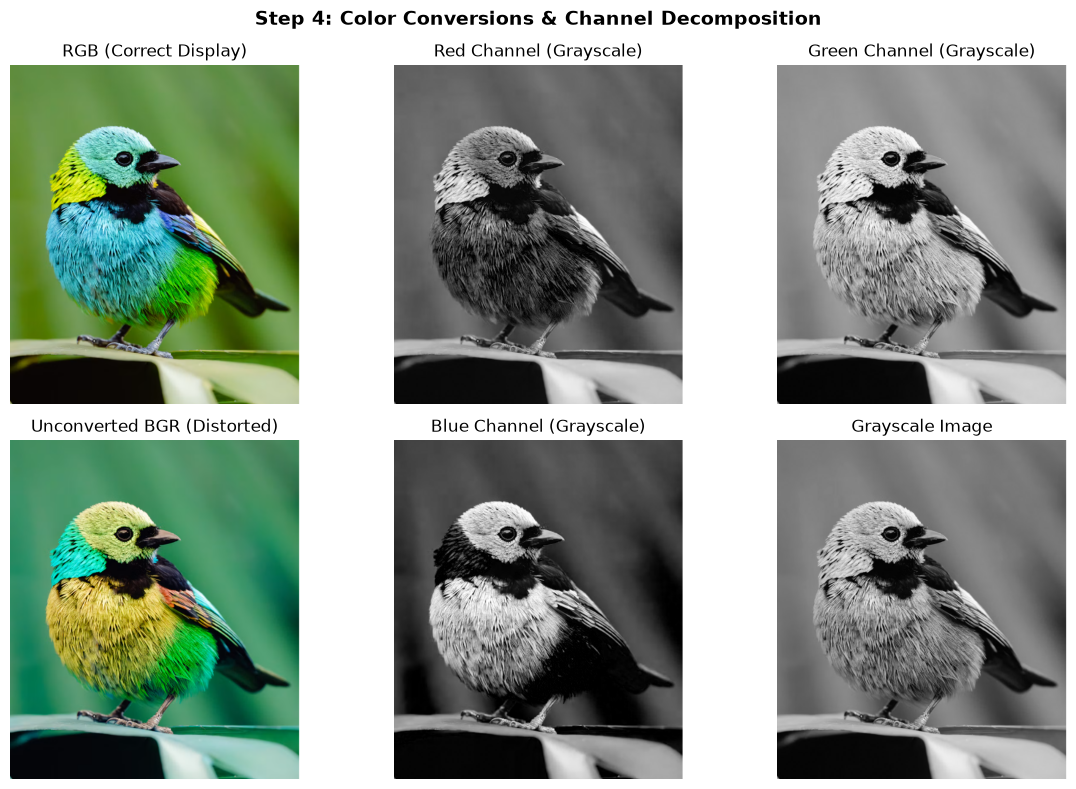


=== [STEP 5: CROP, RESIZE & PERSISTENCE] ===
Crop Coordinates: Y[289:389], X[240:340]
Crop ROI Shape: (100, 100, 3)
Resized Crop Shape: (200, 200, 3)


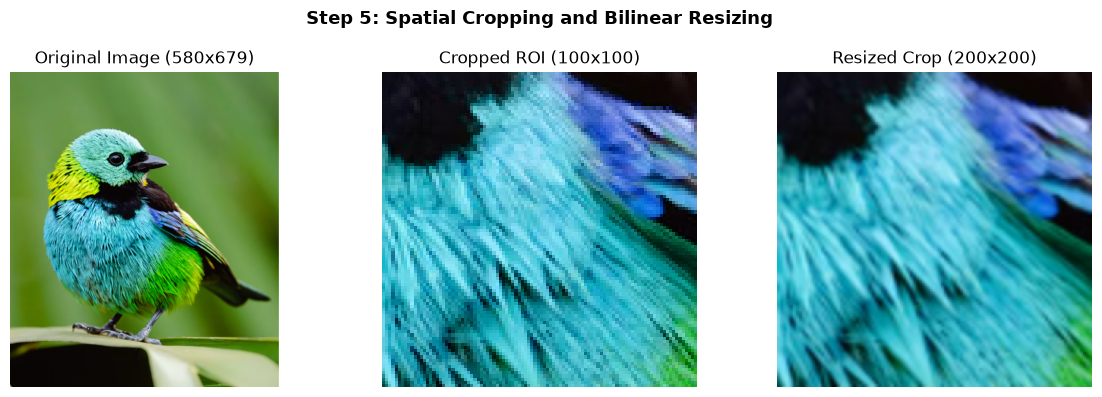

cv.imwrite('resized_crop.png') Success: True

=== [STEP 6: GRAYSCALE HISTOGRAM] ===


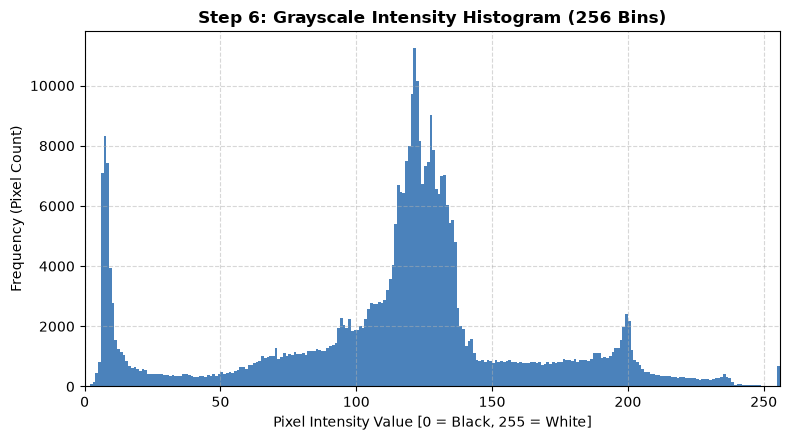

Grayscale Mean Intensity: 113.64
Grayscale Standard Deviation: 50.90

=== [STEP 7: BIT DEPTH DEMONSTRATION] ===
8-bit Unique Levels: 256 (Expected: 256)
4-bit Unique Levels: 16 (Expected: 16)
2-bit Unique Levels: 4 (Expected: 4)
1-bit Unique Levels: 2 (Expected: 2)


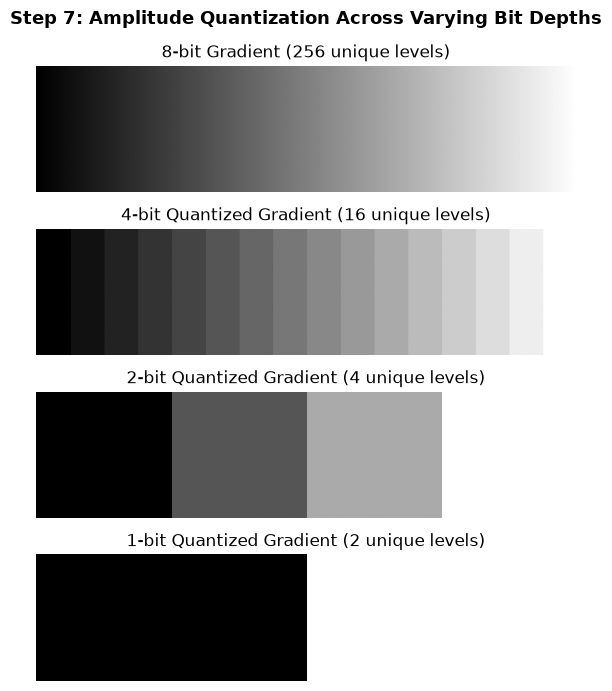


  ALL LAB 02 TASKS COMPLETED SUCCESSFULLY!  


In [2]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Load Image with error handling
IMAGE_PATH = 'sample.png'
if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"[ERROR] Input image '{IMAGE_PATH}' not found in dip-lab-02 directory.")

img_bgr = cv.imread(IMAGE_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"[ERROR] cv.imread failed to load '{IMAGE_PATH}'. Verify file format.")

# Step 3: Inspect Properties & Dynamic Range
height, width, channels = img_bgr.shape
dtype = img_bgr.dtype

print("=== [STEP 2 & 3: IMAGE INSPECTION] ===")
print(f"Dimensions: Height = {height} px, Width = {width} px, Channels = {channels}")
print(f"Shape Tuple: {img_bgr.shape}")
print(f"Data Type: {dtype}")

center_y, center_x = height // 2, width // 2
top_left_pixel = img_bgr[0, 0]
center_pixel = img_bgr[center_y, center_x]

print(f"Top-Left Pixel [0, 0] (BGR): {top_left_pixel}")
print(f"Center Pixel [{center_y}, {center_x}] (BGR): {center_pixel}")
print(f"Global Minimum Intensity: {np.min(img_bgr)}")
print(f"Global Maximum Intensity: {np.max(img_bgr)}")

ch_names = ["Blue Channel", "Green Channel", "Red Channel"]
for idx, name in enumerate(ch_names):
    c_min = np.min(img_bgr[:, :, idx])
    c_max = np.max(img_bgr[:, :, idx])
    print(f"{name} (Index {idx}): Min = {c_min}, Max = {c_max}")

# Step 4: Color Conversions & Channel Decomposition
print("\n=== [STEP 4: COLOR CONVERSIONS & CHANNEL DECOMPOSITION] ===")
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
b_channel, g_channel, r_channel = cv.split(img_bgr)

center_rgb = img_rgb[center_y, center_x]
hex_color = f"#{center_rgb[0]:02X}{center_rgb[1]:02X}{center_rgb[2]:02X}"
print(f"Center Pixel RGB: {center_rgb}")
print(f"Center Pixel HEX Code: {hex_color}")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(img_rgb); axes[0, 0].set_title("RGB (Correct Display)"); axes[0, 0].axis("off")
axes[0, 1].imshow(r_channel, cmap="gray"); axes[0, 1].set_title("Red Channel (Grayscale)"); axes[0, 1].axis("off")
axes[0, 2].imshow(g_channel, cmap="gray"); axes[0, 2].set_title("Green Channel (Grayscale)"); axes[0, 2].axis("off")
axes[1, 0].imshow(img_bgr); axes[1, 0].set_title("Unconverted BGR (Distorted)"); axes[1, 0].axis("off")
axes[1, 1].imshow(b_channel, cmap="gray"); axes[1, 1].set_title("Blue Channel (Grayscale)"); axes[1, 1].axis("off")
axes[1, 2].imshow(img_gray, cmap="gray"); axes[1, 2].set_title("Grayscale Image"); axes[1, 2].axis("off")
plt.suptitle("Step 4: Color Conversions & Channel Decomposition", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("channels_comparison.png", dpi=300)
plt.show()

# Step 5: Crop, Resize, and Save
print("\n=== [STEP 5: CROP, RESIZE & PERSISTENCE] ===")
crop_size = 100
y_start = max(0, center_y - crop_size // 2)
y_end = y_start + crop_size
x_start = max(0, center_x - crop_size // 2)
x_end = x_start + crop_size

crop_rgb = img_rgb[y_start:y_end, x_start:x_end]
print(f"Crop Coordinates: Y[{y_start}:{y_end}], X[{x_start}:{x_end}]")
print(f"Crop ROI Shape: {crop_rgb.shape}")

resized_crop_rgb = cv.resize(crop_rgb, (200, 200), interpolation=cv.INTER_LINEAR)
print(f"Resized Crop Shape: {resized_crop_rgb.shape}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_rgb); axes[0].set_title(f"Original Image ({width}x{height})"); axes[0].axis("off")
axes[1].imshow(crop_rgb); axes[1].set_title("Cropped ROI (100x100)"); axes[1].axis("off")
axes[2].imshow(resized_crop_rgb); axes[2].set_title("Resized Crop (200x200)"); axes[2].axis("off")
plt.suptitle("Step 5: Spatial Cropping and Bilinear Resizing", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("crop_and_resize.png", dpi=300)
plt.show()

resized_crop_bgr = cv.cvtColor(resized_crop_rgb, cv.COLOR_RGB2BGR)
save_status = cv.imwrite("resized_crop.png", resized_crop_bgr)
print(f"cv.imwrite('resized_crop.png') Success: {save_status}")

# Step 6: Grayscale Histogram & Analysis
print("\n=== [STEP 6: GRAYSCALE HISTOGRAM] ===")
plt.figure(figsize=(8, 4.5))
plt.hist(img_gray.ravel(), bins=256, range=[0, 256], color="#2B6CB0", alpha=0.85, edgecolor="none")
plt.title("Step 6: Grayscale Intensity Histogram (256 Bins)", fontsize=12, fontweight="bold")
plt.xlabel("Pixel Intensity Value [0 = Black, 255 = White]")
plt.ylabel("Frequency (Pixel Count)")
plt.xlim([0, 256])
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("grayscale_histogram.png", dpi=300)
plt.show()

mean_val = np.mean(img_gray)
std_val = np.std(img_gray)
print(f"Grayscale Mean Intensity: {mean_val:.2f}")
print(f"Grayscale Standard Deviation: {std_val:.2f}")

# Step 7: Bit Depth Quantization
print("\n=== [STEP 7: BIT DEPTH DEMONSTRATION] ===")
gradient_row = np.linspace(0, 255, 512, dtype=np.uint8)
grad_8bit = np.tile(gradient_row, (120, 1))

grad_1bit = (grad_8bit // 128) * 255
grad_2bit = (grad_8bit // 64) * 85
grad_4bit = (grad_8bit // 16) * 17

u_8bit = len(np.unique(grad_8bit))
u_4bit = len(np.unique(grad_4bit))
u_2bit = len(np.unique(grad_2bit))
u_1bit = len(np.unique(grad_1bit))

print(f"8-bit Unique Levels: {u_8bit} (Expected: 256)")
print(f"4-bit Unique Levels: {u_4bit} (Expected: 16)")
print(f"2-bit Unique Levels: {u_2bit} (Expected: 4)")
print(f"1-bit Unique Levels: {u_1bit} (Expected: 2)")

fig, axes = plt.subplots(4, 1, figsize=(10, 7))
axes[0].imshow(grad_8bit, cmap="gray"); axes[0].set_title(f"8-bit Gradient ({u_8bit} unique levels)"); axes[0].axis("off")
axes[1].imshow(grad_4bit, cmap="gray"); axes[1].set_title(f"4-bit Quantized Gradient ({u_4bit} unique levels)"); axes[1].axis("off")
axes[2].imshow(grad_2bit, cmap="gray"); axes[2].set_title(f"2-bit Quantized Gradient ({u_2bit} unique levels)"); axes[2].axis("off")
axes[3].imshow(grad_1bit, cmap="gray"); axes[3].set_title(f"1-bit Quantized Gradient ({u_1bit} unique levels)"); axes[3].axis("off")
plt.suptitle("Step 7: Amplitude Quantization Across Varying Bit Depths", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("bit_depth_comparison.png", dpi=300)
plt.show()

print("\n" + "=" * 65)
print("  ALL LAB 02 TASKS COMPLETED SUCCESSFULLY!  ")
print("=" * 65)